In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import time

# 1. Configuration & Data
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 64
learning_rate = 1e-3
epochs = 20

# Separate transforms for Training (with randomness) and Test (clean)
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),  # <--- NEW: Flip images left/right
    transforms.RandomRotation(10),      # <--- NEW: Rotate slightly (+/- 10 deg)
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Update your dataset loaders to use these specific transforms
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


#Implementing Autoencoders (AE)

### What is an Autoencoder?
At its heart, an Autoencoder is a neural network designed to learn a compressed, meaningful representation of data. Unlike standard classifiers, this is an unsupervised learning technique—the data itself acts as the label.

It squeezes information down to the essentials and then tries to expand it back to its original form.The Two-Part ArchitectureThe model is split into two distinct functional blocks:

**The Encoder** ($f$): It takes a high-dimensional input $\mathbf{x}$ (like a $28 \times 28$ image).Through a series of layers, it "squeezes" the data into a low-dimensional, dense vector $\mathbf{z}$.This compressed state is known as the Bottleneck or Latent Space.

**The Decoder** ($g$): It takes the tiny latent vector $\mathbf{z}$ as its input.It attempts to "reconstruct" the original data as perfectly as possible, producing $\mathbf{\hat{x}}$.The Goal: Minimize the Reconstruction Loss, usually calculated as $L(\mathbf{x}, \mathbf{\hat{x}}) = \|\mathbf{x} - \mathbf{\hat{x}}\|^2$.

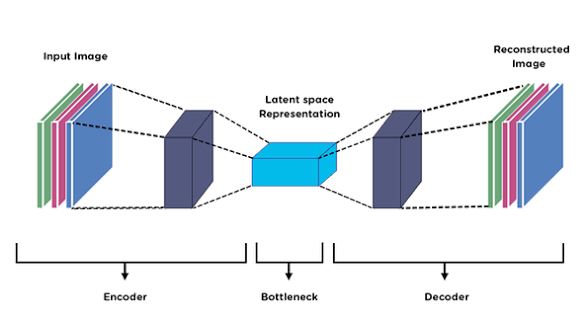

In [2]:
# 2. The Model Architecture
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1), # 32x32 -> 16x16
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), # 16x16 -> 8x8
            nn.ReLU(),
            nn.Conv2d(64, 128, 8) # 8x8 -> 1x1 (The Bottleneck)
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 8), # 1x1 -> 8x8
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), # 8x8 -> 16x16
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 3, stride=2, padding=1, output_padding=1), # 16x16 -> 32x32
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

model = ConvAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# The Denoiser

To turn our Autoencoder into a Denoiser, we add some noise (random values) to the input image, but we tell the Loss Function to compare the output to the original, clean image.

In [3]:
# 1. Noise Function (For Denoiser Mode)
def add_noise(inputs, noise_factor=0.2):
    noise = torch.randn_like(inputs) * noise_factor
    return torch.clamp(inputs + noise, -1., 1.)

In [4]:
# 2. Training Loop
mode = "denoise"
print(f"Starting training in {mode} mode...")
start_total = time.time()  # Start global timer

model.train()
for epoch in range(epochs):
    epoch_start = time.time()  # Start epoch timer
    running_loss = 0.0
    for data, _ in train_loader:
        clean_imgs = data.to(device)

        inputs = add_noise(clean_imgs) #noisy images

        # Standard PyTorch Training Step
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, clean_imgs) # Target is ALWAYS the clean image
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

total_duration = time.time() - start_total
print("-" * 30)
print(f"Training Complete!")
print(f"Total Time: {total_duration/60:.2f} minutes")
print("-" * 30)

Starting training in denoise mode...
Epoch 1/20, Loss: 0.0663
Epoch 2/20, Loss: 0.0294
Epoch 3/20, Loss: 0.0252
Epoch 4/20, Loss: 0.0239
Epoch 5/20, Loss: 0.0233
Epoch 6/20, Loss: 0.0229
Epoch 7/20, Loss: 0.0226
Epoch 8/20, Loss: 0.0224
Epoch 9/20, Loss: 0.0222
Epoch 10/20, Loss: 0.0221
Epoch 11/20, Loss: 0.0220
Epoch 12/20, Loss: 0.0218
Epoch 13/20, Loss: 0.0218
Epoch 14/20, Loss: 0.0216
Epoch 15/20, Loss: 0.0216
Epoch 16/20, Loss: 0.0215
Epoch 17/20, Loss: 0.0214
Epoch 18/20, Loss: 0.0214
Epoch 19/20, Loss: 0.0213
Epoch 20/20, Loss: 0.0213
------------------------------
Training Complete!
Total Time: 8.89 minutes
------------------------------


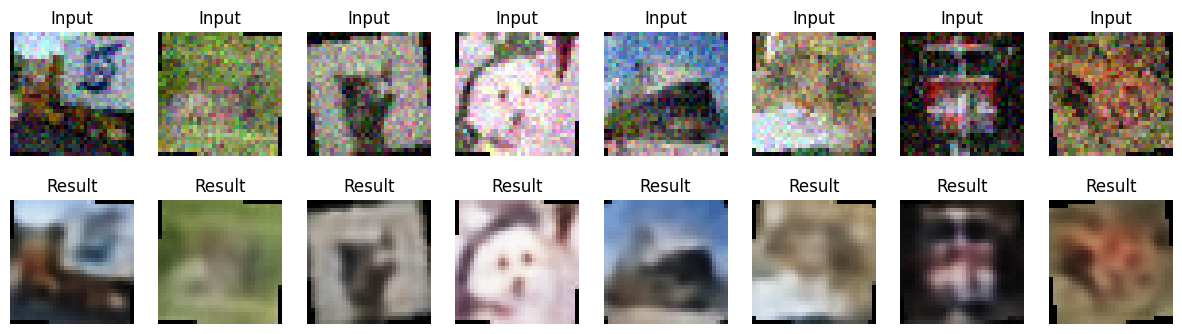

In [5]:
# 3. Visualization
def plot_results(model, loader):
    model.eval()
    with torch.no_grad():
        images, _ = next(iter(loader))
        images = images.to(device)

        inputs = add_noise(images)
        outputs = model(inputs)

        # Move back to CPU and un-normalize for plotting
        inputs = (inputs.cpu() * 0.5 + 0.5).permute(0, 2, 3, 1).numpy()
        outputs = (outputs.cpu() * 0.5 + 0.5).permute(0, 2, 3, 1).numpy()

        fig, axes = plt.subplots(2, 8, figsize=(15, 4))
        for i in range(8):
            axes[0, i].imshow(inputs[i])
            axes[0, i].set_title("Input")
            axes[0, i].axis('off')
            axes[1, i].imshow(outputs[i])
            axes[1, i].set_title("Result")
            axes[1, i].axis('off')
        plt.show()

plot_results(model, train_loader)

# The Image Inpainter
To turn our Autoencoder into an Inpainter, we apply a "mask" (a black square) to the input image, but we tell the Loss Function to compare the output to the original, unmasked image.

In [6]:
# 1. The Masking Function
#This function creates a random 8 x 8 black hole in our 32 x 32 images.

def apply_mask(imgs, mask_size=10):
    """Adds a black square mask to a random location in each image."""
    masked_imgs = imgs.clone()
    n, c, h, w = imgs.shape

    for i in range(n):
        # Randomly pick the top-left corner of the mask
        y = torch.randint(0, h - mask_size, (1,))
        x = torch.randint(0, w - mask_size, (1,))

        # Punch the hole (set pixels to -1.0 because of our normalization)
        masked_imgs[i, :, y:y+mask_size, x:x+mask_size] = -1.0

    return masked_imgs

In [7]:
# 2. Training the inpainter
mode = "Inpainting"
print(f"Starting training in {mode} mode...")
start_total = time.time()  # Start global timer

model.train()

for epoch in range(epochs):
    epoch_start = time.time()  # Start epoch timer
    running_loss = 0.0
    for data, _ in train_loader:
        clean_imgs = data.to(device)

        # Create the "Problem" (Input)
        masked_inputs = apply_mask(clean_imgs)

        # Optimization
        optimizer.zero_grad()
        outputs = model(masked_inputs) # Model sees the hole
        loss = criterion(outputs, clean_imgs) # Loss is against the WHOLE image
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

total_duration = time.time() - start_total
print("-" * 30)
print(f"Training Complete!")
print(f"Total Time: {total_duration/60:.2f} minutes")
print("-" * 30)

Starting training in Inpainting mode...
Epoch 1/20, Loss: 0.0309
Epoch 2/20, Loss: 0.0269
Epoch 3/20, Loss: 0.0264
Epoch 4/20, Loss: 0.0261
Epoch 5/20, Loss: 0.0260
Epoch 6/20, Loss: 0.0259
Epoch 7/20, Loss: 0.0258
Epoch 8/20, Loss: 0.0257
Epoch 9/20, Loss: 0.0257
Epoch 10/20, Loss: 0.0256
Epoch 11/20, Loss: 0.0255
Epoch 12/20, Loss: 0.0255
Epoch 13/20, Loss: 0.0255
Epoch 14/20, Loss: 0.0254
Epoch 15/20, Loss: 0.0253
Epoch 16/20, Loss: 0.0253
Epoch 17/20, Loss: 0.0252
Epoch 18/20, Loss: 0.0253
Epoch 19/20, Loss: 0.0252
Epoch 20/20, Loss: 0.0252
------------------------------
Training Complete!
Total Time: 9.70 minutes
------------------------------


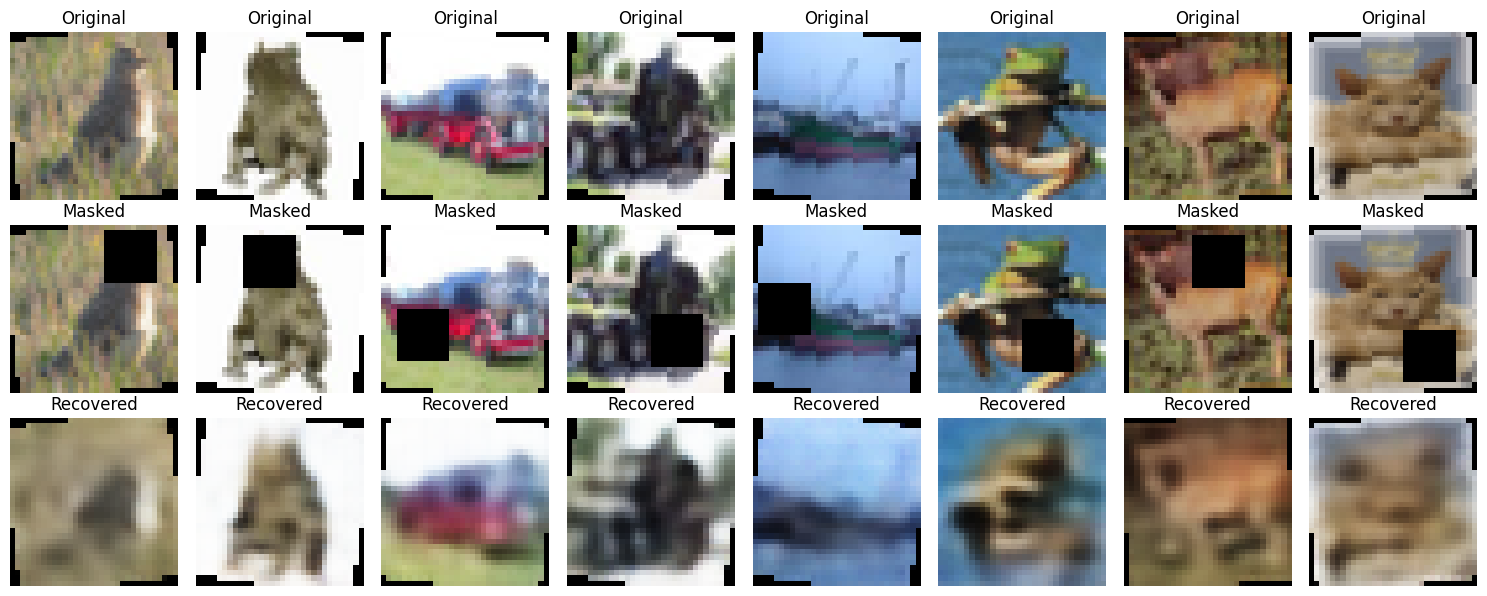

In [8]:
# 3. Visualizing the "Before & After"
def visualize_inpainting(model, loader):
    model.eval()
    with torch.no_grad():
        imgs, _ = next(iter(loader))
        imgs = imgs.to(device)
        masked = apply_mask(imgs)
        reconstructed = model(masked)

        # Convert back to [0, 1] range for plotting
        imgs = imgs.cpu() * 0.5 + 0.5
        masked = masked.cpu() * 0.5 + 0.5
        reconstructed = reconstructed.cpu() * 0.5 + 0.5

        fig, axes = plt.subplots(3, 8, figsize=(15, 6))
        for i in range(8):
            axes[0, i].imshow(imgs[i].permute(1,2,0))
            axes[0, i].set_title("Original")
            axes[1, i].imshow(masked[i].permute(1,2,0))
            axes[1, i].set_title("Masked")
            axes[2, i].imshow(reconstructed[i].permute(1,2,0))
            axes[2, i].set_title("Recovered")
            for ax in axes[:, i]: ax.axis('off')
        plt.tight_layout()
        plt.show()

visualize_inpainting(model, train_loader)

# The Feature Extractor

In [9]:
# 3. Training Loop
mode = "simple"
print(f"Starting training in {mode} mode...")
start_total = time.time()  # Start global timer

model.train()
for epoch in range(epochs):
    running_loss = 0.0
    for data, _ in train_loader:
        clean_imgs = data.to(device)

        inputs = clean_imgs

       # Standard PyTorch Training Step
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, clean_imgs) # Target is ALWAYS the clean image
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

total_duration = time.time() - start_total
print("-" * 30)
print(f"Training Complete!")
print(f"Total Time: {total_duration/60:.2f} minutes")
print("-" * 30)

Starting training in simple mode...
Epoch 1/20, Loss: 0.0193
Epoch 2/20, Loss: 0.0193
Epoch 3/20, Loss: 0.0192
Epoch 4/20, Loss: 0.0192
Epoch 5/20, Loss: 0.0192
Epoch 6/20, Loss: 0.0191
Epoch 7/20, Loss: 0.0191
Epoch 8/20, Loss: 0.0191
Epoch 9/20, Loss: 0.0191
Epoch 10/20, Loss: 0.0190
Epoch 11/20, Loss: 0.0190
Epoch 12/20, Loss: 0.0190
Epoch 13/20, Loss: 0.0190
Epoch 14/20, Loss: 0.0190
Epoch 15/20, Loss: 0.0189
Epoch 16/20, Loss: 0.0189
Epoch 17/20, Loss: 0.0189
Epoch 18/20, Loss: 0.0189
Epoch 19/20, Loss: 0.0189
Epoch 20/20, Loss: 0.0189
------------------------------
Training Complete!
Total Time: 8.94 minutes
------------------------------


In [10]:
# 1. Prepare the Classifier Head
# Our bottleneck is 128
# CIFAR-10 has 10 classes
classifier_head = nn.Sequential(
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.5), # <--- NEW LINE: Randomly zeroes 50% of neurons
    nn.Linear(64, 10)
).to(device)

# 2. Freeze the Autoencoder weights
# This ensures we don't ruin the learned features during classification training
for param in model.encoder.parameters():
    param.requires_grad = False

# 3. Classification Training Loop
cls_criterion = nn.CrossEntropyLoss()
cls_optimizer = optim.Adam(classifier_head.parameters(), lr=1e-3)

model.encoder.eval() # Encoder stays in eval mode
classifier_head.train()

print("Starting Classification Training using Encoder Features...")

for epoch in range(20):
    total_correct = 0
    for data, labels in train_loader:
        imgs, labels = data.to(device), labels.to(device)

        # Pass through Encoder ONLY
        with torch.no_grad(): # Extra safety since weights are frozen
            features = model.encoder(imgs)
            # features shape: [batch, 128, 1, 1] -> needs flattening
            features = features.view(features.size(0), -1)

        # Pass features to our new head
        outputs = classifier_head(features)
        loss = cls_criterion(outputs, labels)

        # Backward pass (only updates classifier_head)
        cls_optimizer.zero_grad()
        loss.backward()
        cls_optimizer.step()

        # Track accuracy
        _, predicted = torch.max(outputs.data, 1)
        total_correct += (predicted == labels).sum().item()

    accuracy = 100 * total_correct / len(train_dataset)
    print(f"Epoch [{epoch+1}/20] | Accuracy: {accuracy:.2f}%")

Starting Classification Training using Encoder Features...
Epoch [1/20] | Accuracy: 30.53%
Epoch [2/20] | Accuracy: 36.85%
Epoch [3/20] | Accuracy: 38.52%
Epoch [4/20] | Accuracy: 39.64%
Epoch [5/20] | Accuracy: 40.00%
Epoch [6/20] | Accuracy: 40.26%
Epoch [7/20] | Accuracy: 40.83%
Epoch [8/20] | Accuracy: 40.78%
Epoch [9/20] | Accuracy: 41.06%
Epoch [10/20] | Accuracy: 41.25%
Epoch [11/20] | Accuracy: 41.25%
Epoch [12/20] | Accuracy: 41.42%
Epoch [13/20] | Accuracy: 41.67%
Epoch [14/20] | Accuracy: 41.55%
Epoch [15/20] | Accuracy: 41.52%
Epoch [16/20] | Accuracy: 41.77%
Epoch [17/20] | Accuracy: 41.58%
Epoch [18/20] | Accuracy: 41.43%
Epoch [19/20] | Accuracy: 41.36%
Epoch [20/20] | Accuracy: 41.59%


In [12]:
def test_classifier(encoder, head, loader):
    encoder.eval()
    head.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for data, labels in loader:
            imgs, labels = data.to(device), labels.to(device)

            # Extract features (No gradients needed)
            features = encoder(imgs)
            features = features.view(features.size(0), -1)

            # Classify
            outputs = head(features) # shape: (batch_size, class_num)

            # Calculate accuracy
            _, predicted = torch.max(outputs.data, 1) # find the max class prob. for each sample
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    return accuracy

# Run the test
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

final_acc = test_classifier(model.encoder, classifier_head, test_loader)
print(f"🚀 Final Test Accuracy: {final_acc:.2f}%")

🚀 Final Test Accuracy: 48.86%


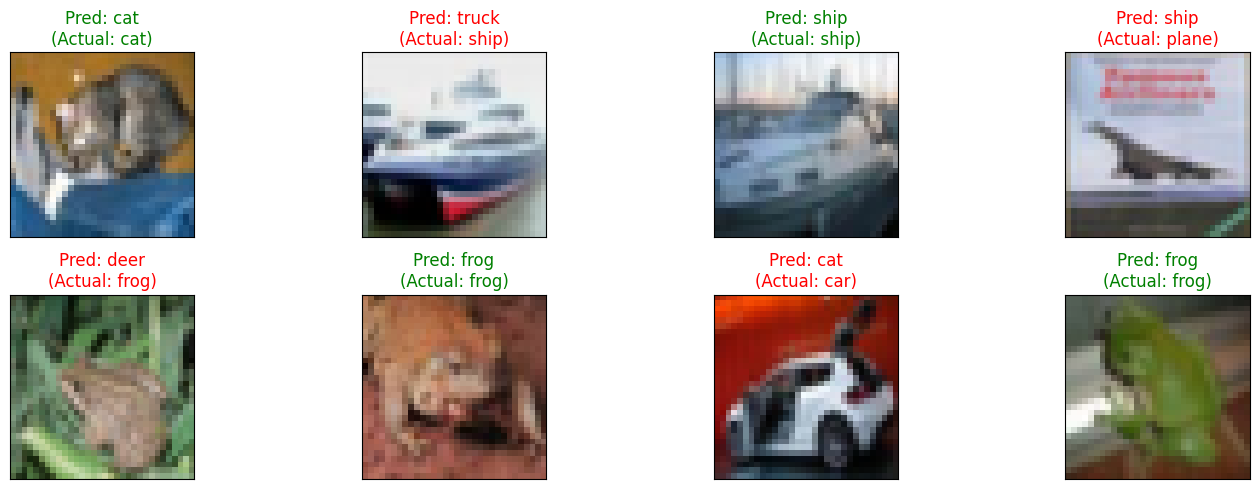

In [13]:
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

def visualize_predictions(encoder, head, loader):
    encoder.eval()
    head.eval()
    imgs, labels = next(iter(loader))
    imgs, labels = imgs.to(device), labels.to(device)

    with torch.no_grad():
        features = encoder(imgs).view(imgs.size(0), -1)
        outputs = head(features)
        _, preds = torch.max(outputs, 1)

    fig = plt.figure(figsize=(15, 5))
    for i in range(8):
        ax = fig.add_subplot(2, 4, i+1, xticks=[], yticks=[])
        # Un-normalize for display
        img_plot = imgs[i].cpu() * 0.5 + 0.5
        plt.imshow(img_plot.permute(1, 2, 0))

        color = "green" if preds[i] == labels[i] else "red"
        ax.set_title(f"Pred: {classes[preds[i]]}\n(Actual: {classes[labels[i]]})", color=color)
    plt.tight_layout()
    plt.show()

visualize_predictions(model.encoder, classifier_head, test_loader)

In [16]:
# ==========================================
# 4. FINE-TUNING (The Secret Weapon)
# ==========================================

print("\n--- Starting Fine-Tuning (Unfreezing Encoder) ---")

# 1. Unfreeze the Encoder
# We now let the Encoder change its weights to help the classification task
for param in model.encoder.parameters():
    param.requires_grad = True

# 2. Lower the Learning Rate
# We use a tiny learning rate so we don't destroy the pre-trained weights
fine_tune_optimizer = optim.Adam(
    list(model.encoder.parameters()) + list(classifier_head.parameters()),
    lr=1e-4  # 10x smaller than before
)

# 3. Fine-Tuning Loop
for epoch in range(50): # Train for 30 more epochs
    total_correct = 0
    running_loss = 0.0

    model.encoder.train() # Set encoder back to train mode
    classifier_head.train()

    for data, labels in train_loader:
        imgs, labels = data.to(device), labels.to(device)

        # Forward pass through everything
        features = model.encoder(imgs).view(imgs.size(0), -1)
        outputs = classifier_head(features)
        loss = cls_criterion(outputs, labels)

        # Backpropagate through EVERYTHING
        fine_tune_optimizer.zero_grad()
        loss.backward()
        fine_tune_optimizer.step()

        # Track accuracy
        _, predicted = torch.max(outputs.data, 1)
        total_correct += (predicted == labels).sum().item()
        running_loss += loss.item()

    accuracy = 100 * total_correct / len(train_dataset)
    print(f"Fine-Tuning Epoch [{epoch+1}/30] | Loss: {running_loss/len(train_loader):.4f} | Accuracy: {accuracy:.2f}%")

# Final Test after Fine-Tuning
final_acc_tuned = test_classifier(model.encoder, classifier_head, test_loader)
print(f"🚀 Final Test Accuracy (After Fine-Tuning): {final_acc_tuned:.2f}%")


--- Starting Fine-Tuning (Unfreezing Encoder) ---
Fine-Tuning Epoch [1/30] | Loss: 1.1190 | Accuracy: 60.09%
Fine-Tuning Epoch [2/30] | Loss: 1.1160 | Accuracy: 60.02%
Fine-Tuning Epoch [3/30] | Loss: 1.1104 | Accuracy: 60.28%
Fine-Tuning Epoch [4/30] | Loss: 1.1092 | Accuracy: 60.33%
Fine-Tuning Epoch [5/30] | Loss: 1.1078 | Accuracy: 60.50%
Fine-Tuning Epoch [6/30] | Loss: 1.0979 | Accuracy: 60.78%
Fine-Tuning Epoch [7/30] | Loss: 1.0911 | Accuracy: 61.17%
Fine-Tuning Epoch [8/30] | Loss: 1.0889 | Accuracy: 60.97%
Fine-Tuning Epoch [9/30] | Loss: 1.0834 | Accuracy: 61.22%
Fine-Tuning Epoch [10/30] | Loss: 1.0838 | Accuracy: 61.20%
Fine-Tuning Epoch [11/30] | Loss: 1.0761 | Accuracy: 61.61%
Fine-Tuning Epoch [12/30] | Loss: 1.0754 | Accuracy: 61.85%
Fine-Tuning Epoch [13/30] | Loss: 1.0675 | Accuracy: 61.92%
Fine-Tuning Epoch [14/30] | Loss: 1.0701 | Accuracy: 62.04%
Fine-Tuning Epoch [15/30] | Loss: 1.0641 | Accuracy: 62.26%
Fine-Tuning Epoch [16/30] | Loss: 1.0573 | Accuracy: 62.32

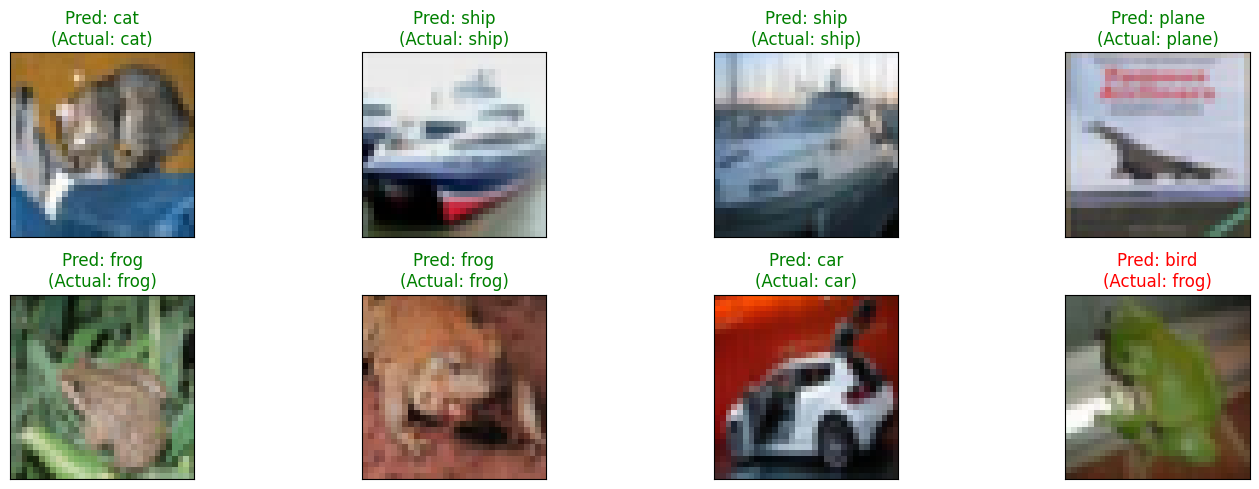

In [17]:
visualize_predictions(model.encoder, classifier_head, test_loader)

In [18]:
torch.save(model.state_dict(), "my_robust_autoencoder.pth")
print("Model saved successfully!")

Model saved successfully!
